Cell 1: โหลดข้อมูลและสรุปสถิติพื้นฐาน

In [8]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from IPython.display import display

# 1. โหลดข้อมูล (ต้องมีไฟล์ forest-area-3.xlsx อยู่โฟลเดอร์เดียวกับ notebook และติดตั้ง openpyxl)
file_name = 'forest-area-3.xlsx'
try:
    df = pd.read_excel(file_name)
except FileNotFoundError:
    df = pd.read_csv('forest-area-3.xlsx - forest-area-km - Copy.csv')

# เรียงข้อมูลตามประเทศและปี เพื่อให้ Lag Feature และค่าปีล่าสุดถูกต้อง
df = df.sort_values(['Entity', 'Year']).reset_index(drop=True)

# 2. แสดงสถิติพื้นฐานรายประเทศ
country_stats = df.groupby('Entity')['Forest area'].agg(['mean', 'min', 'max', 'std']).reset_index()
country_stats.columns = ['Country', 'Mean', 'Min', 'Max', 'Std']

pd.options.display.float_format = '{:,.2f}'.format
print("--- 1. สถิติพื้นที่ป่าแยกตามประเทศ (1990-2025) ---")
display(country_stats)

--- 1. สถิติพื้นที่ป่าแยกตามประเทศ (1990-2025) ---


,Country,Mean,Min,Max,Std
0,Malaysia,"19,508,934.44",18884740,20618500,"492,580.57"
1,Thailand,"20,127,367.78",19647480,20337560,"126,542.82"
2,Vietnam,"12,719,024.17",9375960,14790080,"1,691,432.17"


Cell 2: วิเคราะห์แนวโน้มและการเปลี่ยนแปลง (Trends & % Change)

In [9]:
trend_list = []
for country in df['Entity'].unique():
    c_data = df[df['Entity'] == country].sort_values('Year')
    f_1990 = c_data[c_data['Year'] == 1990]['Forest area'].values[0]
    f_2025 = c_data[c_data['Year'] == 2025]['Forest area'].values[0]

    pct_change = ((f_2025 - f_1990) / f_1990) * 100
    annual_change = (f_2025 - f_1990) / (2025 - 1990)

    trend_list.append({
        "Country": country,
        "% Change (1990-2025)": f"{pct_change:.2f}%",
        "Avg Annual Change (sq.km/yr)": f"{annual_change:,.2f}"
    })

df_trends = pd.DataFrame(trend_list)
print("--- 2. สรุปแนวโน้มการเปลี่ยนแปลงรายประเทศ ---")
display(df_trends)

--- 2. สรุปแนวโน้มการเปลี่ยนแปลงรายประเทศ ---


,Country,% Change (1990-2025),Avg Annual Change (sq.km/yr)
0,Malaysia,-8.41%,"-49,536.00"
1,Thailand,-2.90%,"-16,786.29"
2,Vietnam,57.74%,"154,689.14"


Cell 3: เตรียมข้อมูลและทำ Scaling (เพิ่ม Lag Feature เพื่อความฉลาด)

In [10]:
# 1. สร้าง Lag Feature (พื้นที่ป่าปีที่แล้ว)
df['Prev_Year_Area'] = df.groupby('Entity')['Forest area'].shift(1)
df_model = df.dropna().copy()

# 2. แปลงข้อมูล
le = LabelEncoder()
df_model['Entity_ID'] = le.fit_transform(df_model['Entity'])

scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

X = df_model[['Entity_ID', 'Year', 'Prev_Year_Area']]
y = df_model[['Forest area']]

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

print("✅ เตรียมข้อมูลและเพิ่ม Feature เรียบร้อยแล้ว")

✅ เตรียมข้อมูลและเพิ่ม Feature เรียบร้อยแล้ว


Cell 4: เทรนโมเดลและวัดผลความแม่นยำ (พร้อมค่า Accuracy %)

เพิ่ม $R^2$ Score และ Accuracy (%) ซึ่งคำนวณจาก $(1 - MAPE) \times 100$

In [11]:
# 1. แบ่งข้อมูล Training 80% และ Test 20%
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

# 2. สร้างโมเดล XGBoost
model = xgb.XGBRegressor(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.7,
    random_state=42
)
model.fit(X_train, y_train)

# 3. ฟังก์ชันคำนวณ Metrics
def calculate_metrics(X_data, y_true_scaled, label):
    pred_scaled = model.predict(X_data)
    y_true = scaler_y.inverse_transform(y_true_scaled.reshape(-1, 1))
    y_pred = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1))

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    accuracy = 100 - mape
    return [label, f"{mae:,.2f}", f"{rmse:,.2f}", f"{r2:.4f}", f"{accuracy:.2f}%"]

# 4. แสดงรายงานเปรียบเทียบ
report_data = [
    calculate_metrics(X_train, y_train, "Training Set (ข้อมูลที่ใช้สอน)"),
    calculate_metrics(X_test, y_test, "Test Set (ข้อมูลที่ใช้สอบ/ใหม่)")
]

summary_df = pd.DataFrame(report_data, columns=['Dataset', 'MAE', 'RMSE', 'R2 Score', 'Accuracy (%)'])
print("--- 3. รายงานประสิทธิภาพโมเดล ---")
display(summary_df)

# 5. ความแม่นยำรายประเทศ (Overall) พร้อมคอลัมน์พื้นที่ป่าไม้รวม
y_all_pred = scaler_y.inverse_transform(model.predict(X_scaled).reshape(-1, 1))
df_model['Predicted'] = y_all_pred

country_acc = []
for country in df_model['Entity'].unique():
    # ดึงข้อมูลเฉพาะของประเทศนั้นๆ
    temp = df_model[df_model['Entity'] == country]

    # คำนวณพื้นที่ป่าไม้รวม (Sum) ของประเทศนั้นจากข้อมูลทั้งหมดที่มี
    total_area = temp['Forest area'].sum()

    # คำนวณค่า Metrics
    mae = mean_absolute_error(temp['Forest area'], temp['Predicted'])
    rmse = np.sqrt(mean_squared_error(temp['Forest area'], temp['Predicted']))
    mape = np.mean(np.abs((temp['Forest area'] - temp['Predicted']) / temp['Forest area'])) * 100

    # เก็บข้อมูลลงใน list โดยเรียงลำดับตามที่ต้องการ
    country_acc.append({
        "Country": country,
        "Total Forest Area (Hectares)": f"{total_area:,.2f}", # เพิ่มคอลัมน์นี้
        "MAE": f"{mae:,.2f}",
        "RMSE": f"{rmse:,.2f}",
        "Accuracy (%)": f"{100-mape:.2f}%"
    })

# สร้าง DataFrame และแสดงผล
df_country_summary = pd.DataFrame(country_acc)

print("\n--- 4. ตารางความแม่นยำรายประเทศ พร้อมพื้นที่ป่าไม้รวม ---")
display(df_country_summary)

# เซฟไฟล์รายงานความแม่นยำ
df_country_summary.to_csv('country_accuracy_with_total_area.csv', index=False)

--- 3. รายงานประสิทธิภาพโมเดล ---


,Dataset,MAE,RMSE,R2 Score,Accuracy (%)
0,Training Set (ข้อมูลที่ใช้สอน),"4,774.14","6,536.22",1.0000,99.97%
1,Test Set (ข้อมูลที่ใช้สอบ/ใหม่),"73,459.95","100,230.06",0.9989,99.52%



--- 4. ตารางความแม่นยำรายประเทศ พร้อมพื้นที่ป่าไม้รวม ---


,Country,Total Forest Area (Hectares),MAE,RMSE,Accuracy (%)
0,Malaysia,"681,703,140.00","19,598.40","41,450.31",99.90%
1,Thailand,"704,350,240.00","9,673.66","27,110.78",99.95%
2,Vietnam,"448,508,910.00","26,261.86","60,638.68",99.79%


Cell 5: พยากรณ์ปี 2035 และส่งออกไฟล์สมบูรณ์

In [12]:
future_results = []
for country in df_model['Entity'].unique():
    # ดึงค่าล่าสุดปี 2025 มาเป็นจุดเริ่มต้น
    last_known_area = df[df['Entity'] == country]['Forest area'].iloc[-1]
    c_id = le.transform([country])[0]

    current_area = last_known_area
    for year in range(2026, 2036):
        # สร้างข้อมูล input สำหรับทำนายปีถัดไป
        input_df = pd.DataFrame([[c_id, year, current_area]], columns=['Entity_ID', 'Year', 'Prev_Year_Area'])
        input_scaled = scaler_X.transform(input_df)

        # ทำนาย
        pred_scaled = model.predict(input_scaled)
        pred_real = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1))[0][0]

        future_results.append({'Country': country, 'Year': year, 'Forest area': pred_real, 'Data_Type': 'Forecast'})
        current_area = pred_real # ใช้ค่าที่ทายได้เป็นค่าปีก่อนหน้าของรอบถัดไป

df_future = pd.DataFrame(future_results)

# รวมข้อมูลจริงและพยากรณ์
df_actual = df[['Entity', 'Year', 'Forest area']].copy().rename(columns={'Entity': 'Country'})
df_actual['Data_Type'] = 'Actual'
final_all = pd.concat([df_actual, df_future], ignore_index=True)

# เซฟไฟล์
final_all.to_csv('forest_forecast_hectares_2035.csv', index=False)
print("--- 5. พยากรณ์สำเร็จ! ---")
print(f"ตัวอย่างค่าพยากรณ์ปี 2035:\n{df_future[df_future['Year']==2035]}")
print("\n✅ ดาวน์โหลดไฟล์ 'forest_forecast_hectares_2035.csv' ไปใช้งานได้เลยครับ")

--- 5. พยากรณ์สำเร็จ! ---
ตัวอย่างค่าพยากรณ์ปี 2035:
     Country  Year   Forest area Data_Type
9   Malaysia  2035 18,880,330.00  Forecast
19  Thailand  2035 18,950,738.00  Forecast
29   Vietnam  2035 14,777,636.00  Forecast

✅ ดาวน์โหลดไฟล์ 'forest_forecast_hectares_2035.csv' ไปใช้งานได้เลยครับ


Cell 6: กราฟเส้นแสดงแนวโน้มการเปลี่ยนแปลง (1990 - 2035)

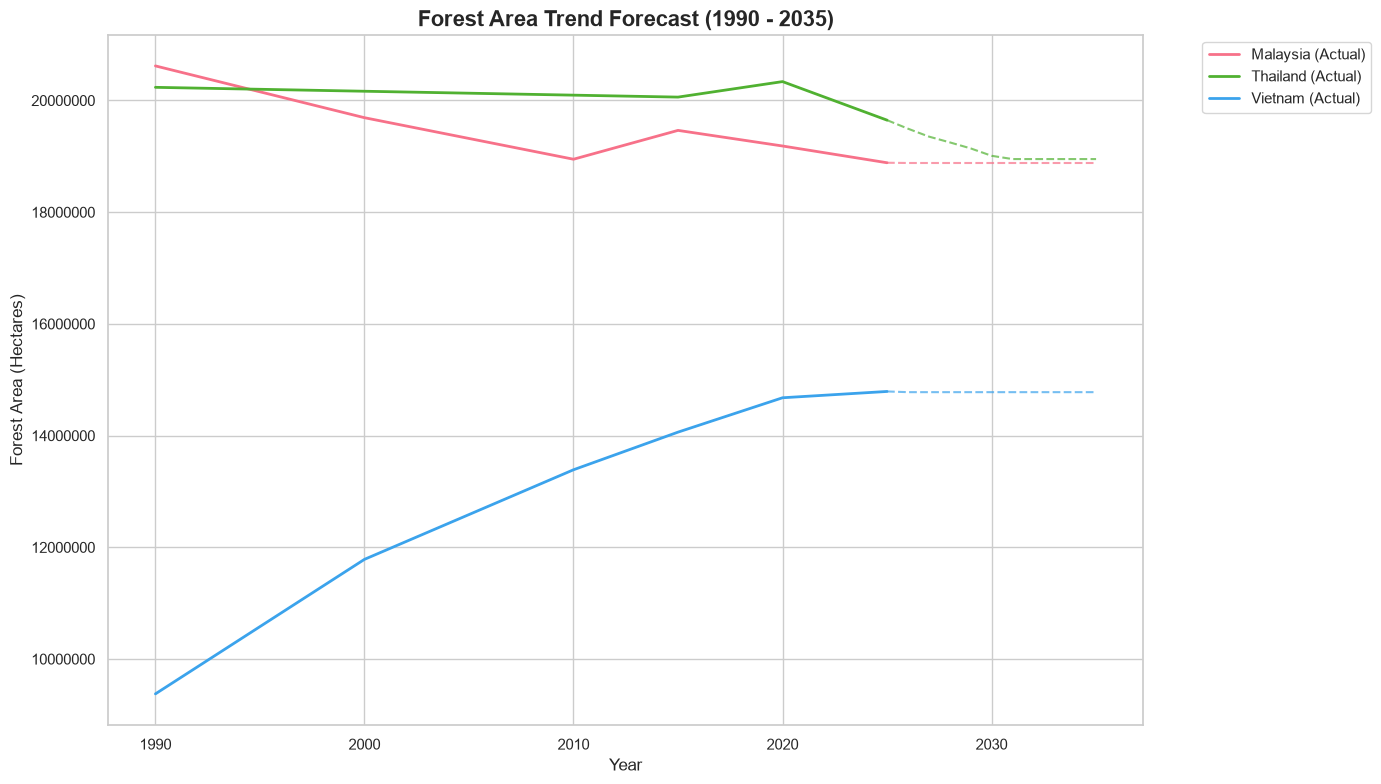

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# ตั้งค่าสไตล์ของกราฟ
sns.set(style="whitegrid")
plt.figure(figsize=(14, 8))

# วาดกราฟเส้นแยกตามประเทศ
countries = final_all['Country'].unique()
colors = sns.color_palette("husl", len(countries))

for i, country in enumerate(countries):
    country_data = final_all[final_all['Country'] == country]

    # แยกข้อมูลจริงและพยากรณ์เพื่อทำสไตล์เส้นที่ต่างกัน
    actual = country_data[country_data['Data_Type'] == 'Actual']
    forecast = country_data[country_data['Data_Type'] == 'Forecast']

    # วาดเส้นข้อมูลจริง (เส้นทึบ)
    plt.plot(actual['Year'], actual['Forest area'], label=f'{country} (Actual)', color=colors[i], linewidth=2)

    # วาดเส้นข้อมูลพยากรณ์ (เส้นปรุ)
    # เชื่อมจุดสุดท้ายของ Actual กับจุดแรกของ Forecast
    last_actual = actual.iloc[-1:]
    forecast_conn = pd.concat([last_actual, forecast])
    plt.plot(forecast_conn['Year'], forecast_conn['Forest area'], linestyle='--', color=colors[i], alpha=0.7)

# ตกแต่งกราฟ
plt.title('Forest Area Trend Forecast (1990 - 2035)', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Forest Area (Hectares)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ticklabel_format(style='plain', axis='y') # ปิดการใช้เลขยกกำลังที่แกน Y
plt.tight_layout()

plt.show()

Cell 7: แผนภูมิแท่งเปรียบเทียบพื้นที่ป่าในปี 2035

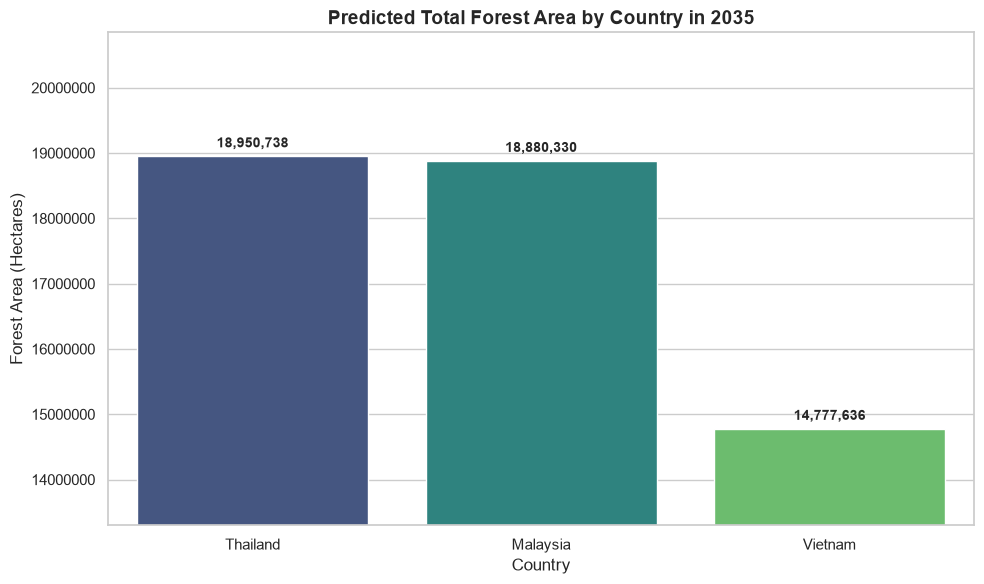

In [14]:
# กรองข้อมูลเฉพาะปี 2035
df_2035 = final_all[final_all['Year'] == 2035].sort_values('Forest area', ascending=False)

plt.figure(figsize=(10, 6))
bar_plot = sns.barplot(x='Country', y='Forest area', hue='Country', data=df_2035, palette='viridis', legend=False)

# ใส่ตัวเลขบนหัวแท่ง
for p in bar_plot.patches:
    bar_plot.annotate(format(p.get_height(), ',.0f'),
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha = 'center', va = 'center',
                   xytext = (0, 9),
                   textcoords = 'offset points',
                   fontsize=10, fontweight='bold')

plt.title('Predicted Total Forest Area by Country in 2035', fontsize=14, fontweight='bold')
plt.ylabel('Forest Area (Hectares)', fontsize=12)
plt.xlabel('Country', fontsize=12)
plt.ticklabel_format(style='plain', axis='y')
plt.ylim(df_2035['Forest area'].min() * 0.9, df_2035['Forest area'].max() * 1.1) # ปรับสเกลแกน Y ให้เห็นความต่างชัดขึ้น

plt.tight_layout()
plt.show()